# Notebook 03 – Exploratory forecasting models

**Role of this notebook.** This notebook is a *descriptive* exploration. It builds a monthly and a weekly blood series, fits a small set of familiar forecasting candidates, and reports rolling-evaluation diagnostics for each. It does **not** pick a final model — that selection is made in Notebook 04 using the rolling window scheme. Any "best" label printed here is diagnostic only.

**What is new relative to the previous version**

- `PredictedBloodDemand` is explained (see §2) and confirmed not to be used as a target or feature.
- Weekly blood series is added because stock is managed at weekly resolution.
- MASE is the primary diagnostic; MAPE is reported but flagged as unreliable for near-zero values.
- Exogenous columns (`HospitalAdmissions`, `Events`, `BloodDonorsAvailable`, `Temperature`) are tested with ARIMAX against the baseline candidates.
- The "selected candidate → 2025 forecast" section has been removed. That belongs in Notebook 05 and is driven by `winning_models.csv` from Notebook 04.
- Data-frame frequency is set explicitly with `asfreq()` and `ValueWarning` is filtered so that ARIMA output is readable.

**Data limitation.** `blood_demand_clean.csv` is synthetic. Results describe this dataset only.

In [11]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Silence the repeated 'No frequency information' warning and
# occasional ARIMAX convergence warnings. MASE is the primary
# metric, so statistical output remains interpretable.
warnings.filterwarnings("ignore", message=".*No frequency information.*")
warnings.filterwarnings("ignore", message=".*Maximum Likelihood optimization failed.*")
warnings.filterwarnings("ignore", message=".*Non-invertible starting.*")

plt.rcParams["figure.figsize"] = (12, 5)
print("Libraries loaded")

Libraries loaded


## 1. Load the cleaned blood-demand dataset

This notebook expects `data/processed/blood_demand_clean.csv`. If the file is missing, run Notebook 01 first. The code does **not** read `Blood_Data.csv`; the cleaned dataset is the modelling input.

In [12]:
data_path = Path("../data/processed/blood_demand_clean.csv")
if not data_path.exists():
    raise FileNotFoundError(
        f"Could not find {data_path.resolve()}. Check the project folder and run Notebook 01 first."
    )

blood = pd.read_csv(data_path)
required_columns = {"Date", "HistoricalBloodUsage"}
missing_columns = required_columns - set(blood.columns)
if missing_columns:
    raise ValueError(f"Missing required columns in blood dataset: {sorted(missing_columns)}")

blood["Date"] = pd.to_datetime(blood["Date"], errors="coerce")
blood["HistoricalBloodUsage"] = pd.to_numeric(blood["HistoricalBloodUsage"], errors="coerce")
blood = (
    blood.dropna(subset=["Date", "HistoricalBloodUsage"])
    .sort_values("Date")
    .drop_duplicates(subset=["Date"], keep="last")
    .set_index("Date")
)
print("Cleaned shape:", blood.shape)
print("Date range:", blood.index.min().date(), "to", blood.index.max().date())
print("Columns:", list(blood.columns))

Cleaned shape: (1827, 9)
Date range: 2020-01-01 to 2024-12-31
Columns: ['DayOfWeek', 'Month', 'Population', 'Events', 'HistoricalBloodUsage', 'HospitalAdmissions', 'BloodDonorsAvailable', 'Temperature', 'PredictedBloodDemand']


## 2. About `PredictedBloodDemand`

The cleaned file contains a column called `PredictedBloodDemand`. It is an artefact of the synthetic data generator (a pre-computed demand estimate). It is **not** produced by any model in this project, and it is **not** used here as a target or as a feature. Using it would be circular — we would be validating a forecast with another forecast that we did not build.

The forecast target throughout this project is `HistoricalBloodUsage`.

The columns `HospitalAdmissions`, `Events`, `BloodDonorsAvailable`, and `Temperature` are **not** ignored. They are tested as exogenous regressors in §6, and the outcome of that test is reported honestly whether or not it helps.

## 3. Build the monthly and weekly blood series

- **Monthly** target: mean of daily `HistoricalBloodUsage` within each month.
- **Weekly** target: sum of `HistoricalBloodUsage` within each ISO week. Used because hospitals manage blood stock week-to-week.

The `asfreq()` call is what removes the `ValueWarning: No frequency information was provided` warning in later statsmodels fits.

Monthly: 60 obs  2020-01-01 → 2024-12-01
Weekly : 262 obs  2020-01-05 → 2025-01-05


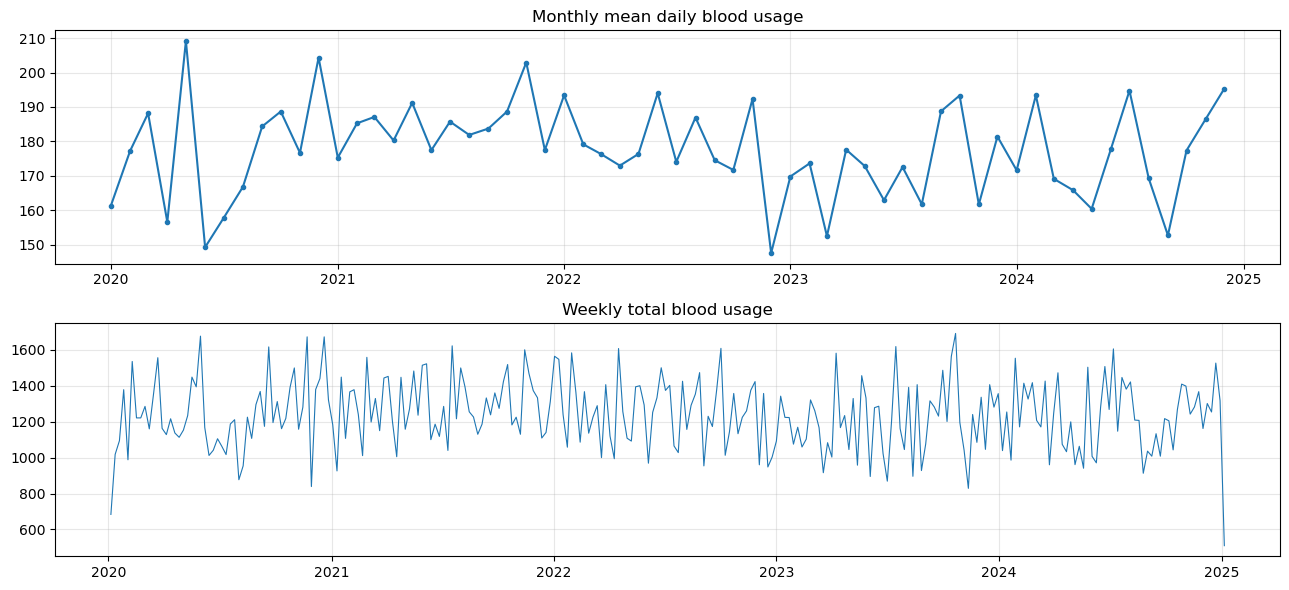

In [13]:
monthly_blood = (
    blood["HistoricalBloodUsage"]
    .resample("MS")
    .mean()
    .dropna()
    .asfreq("MS")
    .astype(float)
)
monthly_blood.name = "MeanDailyBloodUsage"

weekly_blood = (
    blood["HistoricalBloodUsage"]
    .resample("W-SUN")
    .sum()
    .dropna()
    .asfreq("W-SUN")
    .astype(float)
)
weekly_blood.name = "WeeklyBloodUsage"

if monthly_blood.isna().any():
    raise ValueError("Monthly series contains missing months")
if weekly_blood.isna().any():
    raise ValueError("Weekly series contains missing weeks")

print(f"Monthly: {len(monthly_blood)} obs  {monthly_blood.index.min().date()} → {monthly_blood.index.max().date()}")
print(f"Weekly : {len(weekly_blood)} obs  {weekly_blood.index.min().date()} → {weekly_blood.index.max().date()}")

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=False)
axes[0].plot(monthly_blood.index, monthly_blood.values, marker="o", markersize=3)
axes[0].set_title("Monthly mean daily blood usage")
axes[0].grid(alpha=0.3)
axes[1].plot(weekly_blood.index, weekly_blood.values, linewidth=0.8)
axes[1].set_title("Weekly total blood usage")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Prepare exogenous features for ARIMAX

Four columns from the cleaned file are used as candidate exogenous regressors for the weekly blood series. They are aggregated to weekly resolution using a sensible rule (mean for level-type columns, sum for count-type columns).

In [14]:
exog_weekly = pd.DataFrame({
    "Admissions": blood["HospitalAdmissions"].resample("W-SUN").mean(),
    "Events":     blood["Events"].resample("W-SUN").sum(),
    "Donors":     blood["BloodDonorsAvailable"].resample("W-SUN").mean(),
    "Temp":       blood["Temperature"].resample("W-SUN").mean(),
}).asfreq("W-SUN").dropna()

exog_weekly = exog_weekly.reindex(weekly_blood.index)
if exog_weekly.isna().any().any():
    print("Warning: exogenous frame has gaps after reindex; ARIMAX fits will use available rows only.")
print("Exogenous frame shape:", exog_weekly.shape)
display(exog_weekly.head())

Exogenous frame shape: (262, 4)


,Admissions,Events,Donors,Temp
Date,,,,
2020-01-05,81.400000,0,70.400000,30.738730
2020-01-12,47.142857,0,60.285714,26.227319
2020-01-19,57.428571,1,49.714286,27.745633
2020-01-26,65.857143,1,76.428571,27.204038
2020-02-02,59.714286,1,78.714286,29.499765


## 5. Metrics

- **MAE** — average error in original units.
- **MASE** — scaled by in-sample seasonal-naive error; scale-free, handles zero observations. **Primary metric.**
- **MAPE** — reported but flagged as unreliable for intermittent or near-zero series.

In [15]:
def metrics(actual, predicted, train, seasonality):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = float(np.mean(np.abs(actual - predicted)))

    if len(train) > seasonality:
        naive_err = np.abs(train.values[seasonality:] - train.values[:-seasonality])
        denom = float(np.mean(naive_err)) if len(naive_err) else 0.0
        mase = mae / denom if denom > 0 else np.nan
    else:
        mase = np.nan

    with np.errstate(divide="ignore", invalid="ignore"):
        mask = actual != 0
        mape = (float(np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100)
                if mask.any() else np.nan)

    return {"MAE": mae, "MASE": mase, "MAPE": mape}

## 6. Candidate models

The same candidate set is applied to both the monthly and the weekly series, so the two views are comparable:

- **Training mean** — arithmetic average of the training window.
- **Naive** — last observed value.
- **Seasonal naive** — value one full season earlier (12 months / 52 weeks). Falls back to last observation if history is shorter than a season.
- **SES** — level-only exponential smoothing.
- **ARIMA(0,1,1)** — first-differenced, single moving-average term.
- **ARIMAX** — ARIMA(1,0,1) with the four exogenous features above (weekly only).

For each candidate the notebook computes MAE, MASE, and MAPE on a rolling one-step-ahead evaluation.

In [16]:
def rolling_evaluate(series, models, min_train, season, exog=None):
    rows = []
    for i in range(min_train, len(series)):
        train = series.iloc[:i]
        test = float(series.iloc[i])
        train_exog = exog.iloc[:i] if exog is not None else None
        test_exog = exog.iloc[i:i + 1] if exog is not None else None

        for m in models:
            try:
                if m == "Training mean":
                    pred = float(train.mean())
                elif m == "Naive":
                    pred = float(train.iloc[-1])
                elif m == "Seasonal naive":
                    if len(train) >= season:
                        pred = float(train.iloc[-season])
                    else:
                        pred = float(train.iloc[-1])
                elif m == "SES":
                    fit = SimpleExpSmoothing(train, initialization_method="estimated").fit(optimized=True)
                    pred = float(fit.forecast(1).iloc[0])
                elif m == "ARIMA(0,1,1)":
                    fit = ARIMA(train, order=(0, 1, 1)).fit()
                    pred = float(fit.forecast(1).iloc[0])
                elif m == "ARIMAX(all exog)":
                    fit = SARIMAX(
                        endog=train.values, exog=train_exog.values,
                        order=(1, 0, 1), trend="c",
                        enforce_stationarity=False, enforce_invertibility=False,
                    ).fit(disp=False)
                    pred = float(fit.forecast(1, exog=test_exog.values)[0])
                else:
                    continue

                row = {"Model": m, "Step": i, "Actual": test, "Predicted": pred}
                row.update(metrics([test], [pred], train, seasonality=season))
                rows.append(row)
            except Exception:
                continue
    return pd.DataFrame(rows)

### 6.1 Blood — monthly and weekly evaluations

In [ ]:
monthly_models = ["Training mean", "Naive", "Seasonal naive", "SES", "ARIMA(0,1,1)"]
weekly_models = monthly_models + ["ARIMAX(all exog)"]

print("Rolling evaluation: monthly blood")
monthly_results = rolling_evaluate(monthly_blood, monthly_models, min_train=24, season=12)
print("  steps evaluated:", monthly_results.groupby('Model')['MAE'].size().to_dict())

print("Rolling evaluation: weekly blood (with ARIMAX)")
weekly_results = rolling_evaluate(weekly_blood, weekly_models, min_train=52, season=52, exog=exog_weekly)
print("  steps evaluated:", weekly_results.groupby('Model')['MAE'].size().to_dict())

Rolling evaluation: monthly blood
  steps evaluated: {'ARIMA(0,1,1)': 36, 'Naive': 36, 'SES': 36, 'Seasonal naive': 36, 'Training mean': 36}
Rolling evaluation: weekly blood (with ARIMAX)


## 7. Aggregate and read

The tables below are diagnostic — they describe how each candidate performed. **No selection is made in this notebook.** Selection on the rolling-window result is Notebook 04's job.

In [ ]:
def summarise(df, label):
    out = (
        df.groupby("Model")
          .agg(Avg_MAE=("MAE", "mean"),
               Avg_MASE=("MASE", "mean"),
               Avg_MAPE=("MAPE", "mean"),
               N_steps=("MAE", "size"))
          .reset_index()
          .sort_values("Avg_MASE")
    )
    print(f"\n=== {label} ===")
    display(out.round(4))
    return out

monthly_summary = summarise(monthly_results, "Monthly blood")
weekly_summary = summarise(weekly_results, "Weekly blood")

### 7.1 Did exogenous variables help weekly blood?

If ARIMAX does not beat the best pure time-series candidate on MASE, the honest finding is: the exogenous variables do not add predictive value on this synthetic dataset. That is a valid result and is what Notebook 04 will report to Notebook 05.

In [ ]:
best_pure = weekly_summary[weekly_summary.Model != "ARIMAX(all exog)"].iloc[0]
arimax_row = weekly_summary[weekly_summary.Model == "ARIMAX(all exog)"]

print("Best pure time-series on weekly blood:", best_pure.Model, "MASE =", round(best_pure.Avg_MASE, 4))
if not arimax_row.empty:
    a = arimax_row.iloc[0]
    diff = (a.Avg_MASE - best_pure.Avg_MASE) / best_pure.Avg_MASE * 100
    print(f"ARIMAX(all exog) MASE = {a.Avg_MASE:.4f}  ({diff:+.1f}% vs best pure)")
    if a.Avg_MASE < best_pure.Avg_MASE:
        print("=> Exogenous variables improve weekly blood MASE on this data.")
    else:
        print("=> Exogenous variables do not improve weekly blood MASE.")
        print("   Admissions / events / donors / temperature add no measurable")
        print("   predictive value beyond the time-series structure.")
        print("   This is a valid finding and will be carried into Notebook 04.")

## 8. What happens next

- The model comparison that determines which candidate is used for the final forecasts lives in **Notebook 04**. This notebook stops at the diagnostic stage.
- **Notebook 05** reads `winning_models.csv` produced by Notebook 04 and produces final forecasts and stock decisions.
- Any reference to "11.39 / 11.35 / 11.65" style numbers — or to a final selected model — belongs in Notebook 04 or 05, not here.